[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/UWblNSKPRIME/pattern-recognition-practice/blob/main/notebooks/PR5_%D0%91%D0%B0%D0%B1%D0%B8%D1%87_%D0%9A%D0%B8%D1%80%D0%B8%D0%BB%D0%BE.ipynb)

# Практична робота 5. Кластеризація рукописних цифр без вчителя

**Студент:** Бабич Кирило | **Група:** ІН-42/2 | **Дата:** 16.11.2026

**Мета роботи:** Навчитися знаходити природні групи (кластери) в нерозмічених зображеннях рукописних цифр за допомогою трьох підходів кластеризації (*K-Means*, *ієрархічної кластеризації Ward* та *DBSCAN* у поєднанні з *t-SNE*), оцінювати їхню якість без підглядання у мітки та з підгляданням (`ARI`), а також застосовувати кластеризацію для економії бюджету ручної розмітки.

### Словничок термінів
| Термін | Пояснення простими словами |
|---|---|
| **Кластеризація** | Автоматичне групування схожих об'єктів без відомих правильних відповідей (навчання без вчителя). |
| **Центроїд** | «Середній портрет» кластера, точка в центрі групи об'єктів. |
| **K-Means** | Метод, який розбиває дані на наперед задану кількість $K$ компактних сферичних груп. |
| **Ієрархічна кластеризація (Ward)** | Побудова дерева злиттів (дендрограми) від окремих точок до єдиного кластера. |
| **DBSCAN** | Щільнісний алгоритм, який знаходить групи довільної форми та позначає ізольовані точки як шум (`-1`). |
| **t-SNE** | Нелінійне зниження розмірності для візуалізації багатовимірних даних на 2D-площині зі збереженням локальних сусідств. |
| **Silhouette Score** | Метрика якості кластеризації без міток (від `-1` до `+1`): чим ближче до `1`, тим чіткіші групи. |
| **ARI (Adjusted Rand Index)** | Метрика збігу знайдених кластерів зі справжніми класами (`0` — випадково, `1.0` — ідеально). |

---
## Розділ 0. Налаштування середовища та допоміжні функції

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import adjusted_rand_score, silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

SEED = 42
np.random.seed(SEED)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

REPORTS_DIR = Path("../reports") if Path.cwd().name == "notebooks" else Path("reports")
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

def cluster_metrics(X, labels):
    mask = labels != -1
    n_clusters = len(set(labels) - {-1})
    covered = float(mask.mean() * 100)
    sil = float(silhouette_score(X[mask], labels[mask])) if len(set(labels[mask])) > 1 else np.nan
    return {"груп": n_clusters, "охоплено, %": round(covered, 1), "silhouette": round(sil, 4) if not np.isnan(sil) else np.nan}

def plot_clusters(ax, X2, labels, title, s=10):
    unique_labels = sorted(set(labels))
    cmap = plt.get_cmap("tab10")
    for lbl in unique_labels:
        mask = labels == lbl
        if lbl == -1:
            ax.scatter(X2[mask, 0], X2[mask, 1], c="lightgray", s=s, alpha=0.6, label="Шум (-1)", edgecolors="k", linewidths=0.2)
        else:
            ax.scatter(X2[mask, 0], X2[mask, 1], color=cmap(lbl % 10), s=s, alpha=0.75, label=f"C{lbl}")
    ax.set_title(title, fontsize=10)
    if len(unique_labels) <= 12:
        ax.legend(markerscale=1.4, fontsize=7, ncol=2, frameon=True)

def show_digits(images, titles=None, n_cols=10, figsize_per=(1.2, 1.3), suptitle=None):
    n = len(images)
    n_rows = int(np.ceil(n / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * figsize_per[0], n_rows * figsize_per[1]))
    axes = np.atleast_2d(axes)
    for i in range(n_rows * n_cols):
        ax = axes.flat[i]
        ax.axis("off")
        if i < n:
            ax.imshow(images[i].reshape(8, 8), cmap="gray_r")
            if titles is not None:
                ax.set_title(str(titles[i]), fontsize=8)
    if suptitle:
        plt.suptitle(suptitle, fontsize=11, y=1.02)
    plt.tight_layout()
    plt.show()

def cluster_gallery(X_data, labels, n_clusters=10, n_examples=5):
    fig, axes = plt.subplots(n_clusters, n_examples + 1, figsize=((n_examples + 1) * 1.15, n_clusters * 1.1))
    for c in range(n_clusters):
        idx = np.where(labels == c)[0]
        mean_img = X_data[idx].mean(axis=0).reshape(8, 8)
        axes[c, 0].imshow(mean_img, cmap="viridis")
        axes[c, 0].set_title(f"C{c} (n={len(idx)})", fontsize=8, fontweight="bold")
        axes[c, 0].axis("off")
        for j in range(n_examples):
            axes[c, j + 1].axis("off")
            if j < len(idx):
                axes[c, j + 1].imshow(X_data[idx[j]].reshape(8, 8), cmap="gray_r")
    plt.suptitle("Середні портрети кластерів та приклади цифр", fontsize=12, y=1.01)
    plt.tight_layout()
    plt.show()

print("REPORTS_DIR =", REPORTS_DIR.resolve())

REPORTS_DIR = D:\Pr folder\!Розпізнавання образів та класичне машинне навчання\11\reports


---
## Розділ 1. Завантаження даних та первинне дослідження (`digits`)
### 1.1 «Що бачимо ми» vs «Що «бачить» комп’ютер»

Форма X_img: (1797, 64), діапазон значень: [0.0, 16.0]
Перший вектор (64 числа): [0, 0, 5, 13, 9, 1, 0, 0, 0, 0, 13, 15, 10, 15, 5, 0, 0, 3, 15, 2, 0, 11, 8, 0, 0, 4, 12, 0, 0, 8, 8, 0, 0, 5, 8, 0, 0, 9, 8, 0, 0, 4, 11, 0, 1, 12, 7, 0, 0, 2, 14, 5, 10, 12, 0, 0, 0, 0, 6, 13, 10, 0, 0, 0]


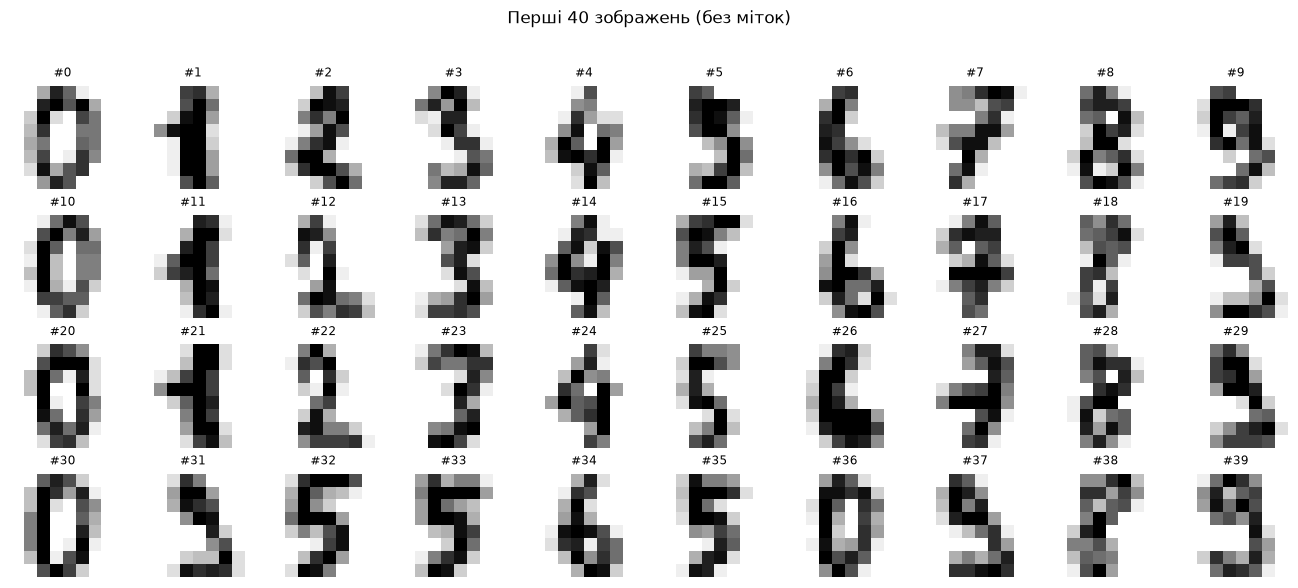

In [2]:
digits = load_digits()
X_img = digits.data
y_true = digits.target

print(f"Форма X_img: {X_img.shape}, діапазон значень: [{X_img.min():.1f}, {X_img.max():.1f}]")
print("Перший вектор (64 числа):", X_img[0].astype(int).tolist())
show_digits(X_img[:40], titles=[f"#{i}" for i in range(40)], n_cols=10, suptitle="Перші 40 зображень (без міток)")

### 1.2 Відстані між зображеннями (`a = X_img[0], b = X_img[10], c = X_img[1]`)

In [3]:
a, b, c = X_img[0], X_img[10], X_img[1]
d_ab = np.linalg.norm(a - b)
d_ac = np.linalg.norm(a - c)
print(f"Відстань між #0 (цифра {y_true[0]}) та #10 (цифра {y_true[10]}): {d_ab:.2f}")
print(f"Відстань між #0 (цифра {y_true[0]}) та #1  (цифра {y_true[1]}): {d_ac:.2f}")

Відстань між #0 (цифра 0) та #10 (цифра 0): 23.71
Відстань між #0 (цифра 0) та #1  (цифра 1): 59.56


### 1.3 Найближчі сусіди (`NearestNeighbors(n_neighbors=9)`) для `[0, 4, 7, 25]`

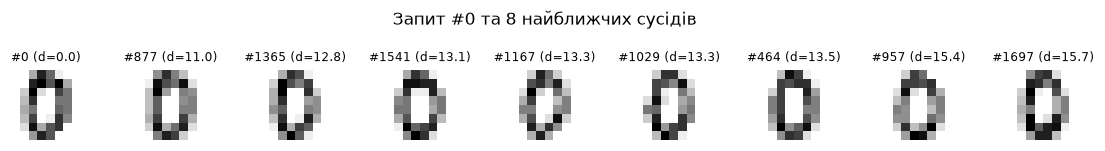

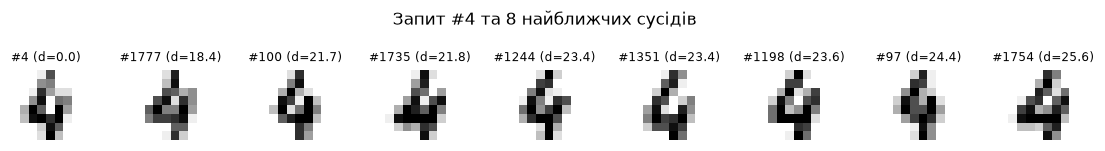

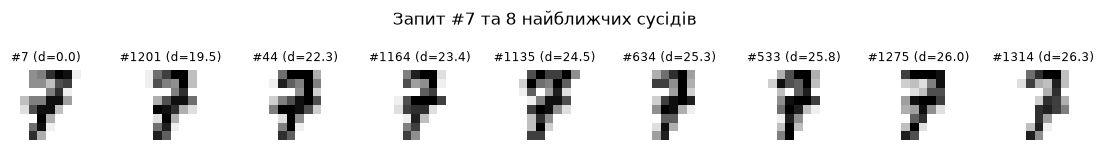

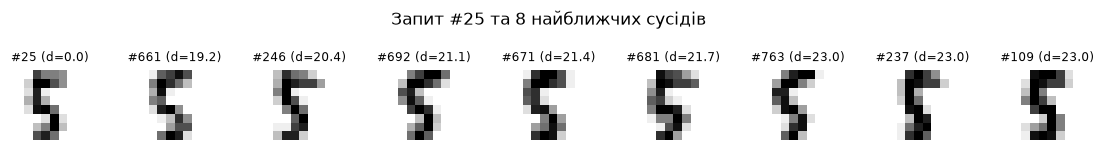

In [4]:
nn = NearestNeighbors(n_neighbors=9).fit(X_img)
for q_idx in [0, 4, 7, 25]:
    dists, idxs = nn.kneighbors([X_img[q_idx]])
    show_digits(X_img[idxs[0]], titles=[f"#{i} (d={d:.1f})" for i, d in zip(idxs[0], dists[0])],
                n_cols=9, figsize_per=(1.15, 1.3), suptitle=f"Запит #{q_idx} та 8 найближчих сусідів")

### 1.4 Вплив стандартизації (`X_std`): заповненість та максимальне значення після скейлінгу

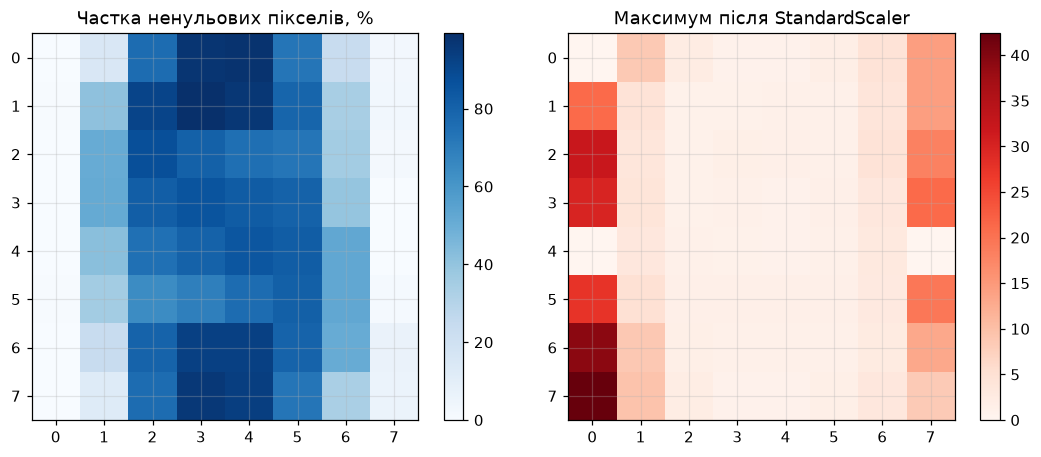

Кутовий піксель #56: ненульових = 0.06%, max після StandardScaler = 42.38
Центральний піксель #27: ненульових = 85.53%, max після StandardScaler = 1.22


In [5]:
X_std = StandardScaler().fit_transform(X_img)
filled_pct = ((X_img > 0).mean(axis=0) * 100).reshape(8, 8)
max_after = X_std.max(axis=0).reshape(8, 8)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
im0 = axes[0].imshow(filled_pct, cmap="Blues")
axes[0].set_title("Частка ненульових пікселів, %")
plt.colorbar(im0, ax=axes[0])

im1 = axes[1].imshow(max_after, cmap="Reds")
axes[1].set_title("Максимум після StandardScaler")
plt.colorbar(im1, ax=axes[1])
plt.tight_layout()
plt.show()

print(f"Кутовий піксель #56: ненульових = {(X_img[:, 56] > 0).mean()*100:.2f}%, max після StandardScaler = {X_std[:, 56].max():.2f}")
print(f"Центральний піксель #27: ненульових = {(X_img[:, 27] > 0).mean()*100:.2f}%, max після StandardScaler = {X_std[:, 27].max():.2f}")

### Зупинка 1 — Відповідь студента
1. **Що бачить комп'ютер замість картинки?** Комп'ютер бачить вектор із **64 чисел** (інтенсивностей пікселів від `0` до `16`), а схожість оцінює через евклідову відстань у 64-вимірному просторі.
2. **Чому відстань між `#0` та `#10` менша, ніж між `#0` та `#1`?** Зображення `#0` і `#10` — це однакова цифра (`0`), тому їхні штрихи перекриваються, а `#1` — це інша цифра (`1`), тому відстань до неї більша.
3. **Чи збігаються 8 найближчих сусідів із тією самою цифрою?** Так, у переважній більшості випадків найближчі сусіди за евклідовою відстанню мають таку саму форму написання.
4. **Чому `StandardScaler` роздуває кутовий піксель `#56` порівняно з центральним `#27`?** Кутовий піксель `#56` майже завжди дорівнює `0` (має мізерну дисперсію), тому ділення на мале стандартне відхилення перетворює рідкісні випадкові штрихи в ньому на величезні викиди.

---
## Розділ 2. K-Means: пошук центроїдів та вибір $K$
### 2.1 Метод ліктя (Inertia) та Silhouette Score для `range(2, 16)`

Максимум Silhouette Score: K=9 (0.1891); при K=10: 0.1824


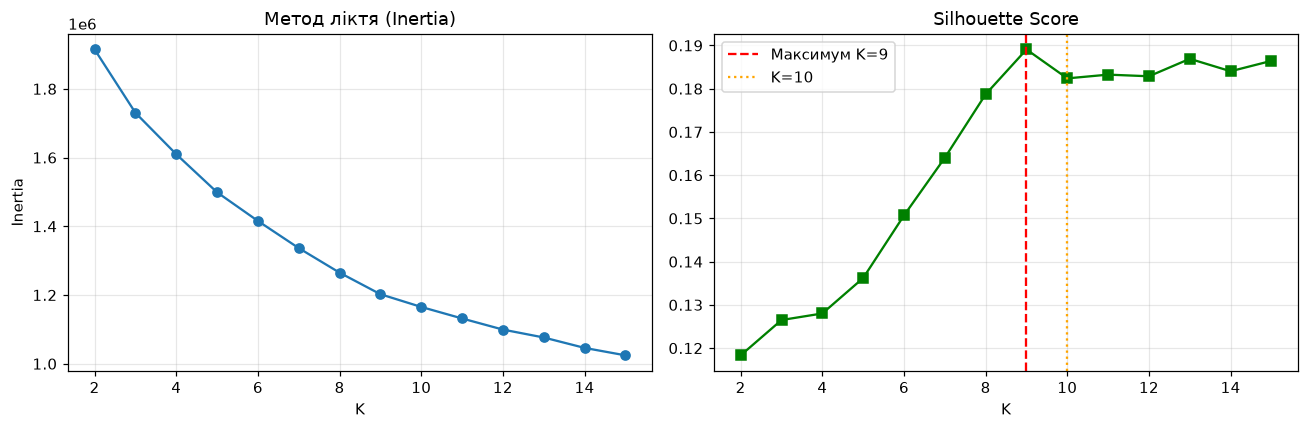

In [6]:
ks = list(range(2, 16))
inertias, sil_scores = [], []
for k in ks:
    km_tmp = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_img)
    inertias.append(km_tmp.inertia_)
    sil_scores.append(silhouette_score(X_img, km_tmp.labels_))

best_k = ks[int(np.argmax(sil_scores))]
print(f"Максимум Silhouette Score: K={best_k} ({max(sil_scores):.4f}); при K=10: {sil_scores[ks.index(10)]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks, inertias, "o-")
axes[0].set_title("Метод ліктя (Inertia)")
axes[0].set_xlabel("K")
axes[0].set_ylabel("Inertia")

axes[1].plot(ks, sil_scores, "s-", color="green")
axes[1].axvline(best_k, color="red", linestyle="--", label=f"Максимум K={best_k}")
axes[1].axvline(10, color="orange", linestyle=":", label="K=10")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("K")
axes[1].legend()
plt.tight_layout()
plt.show()

### 2.2 Навчання `KMeans(n_clusters=10, n_init=20, random_state=SEED)` та галерея кластерів

Розміри кластерів K-Means: [175, 179, 206, 91, 149, 247, 167, 178, 223, 182]
Метрики K-Means: {'груп': 10, 'охоплено, %': 100.0, 'silhouette': 0.1825}


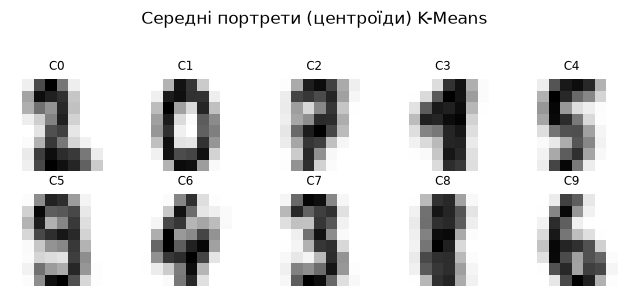

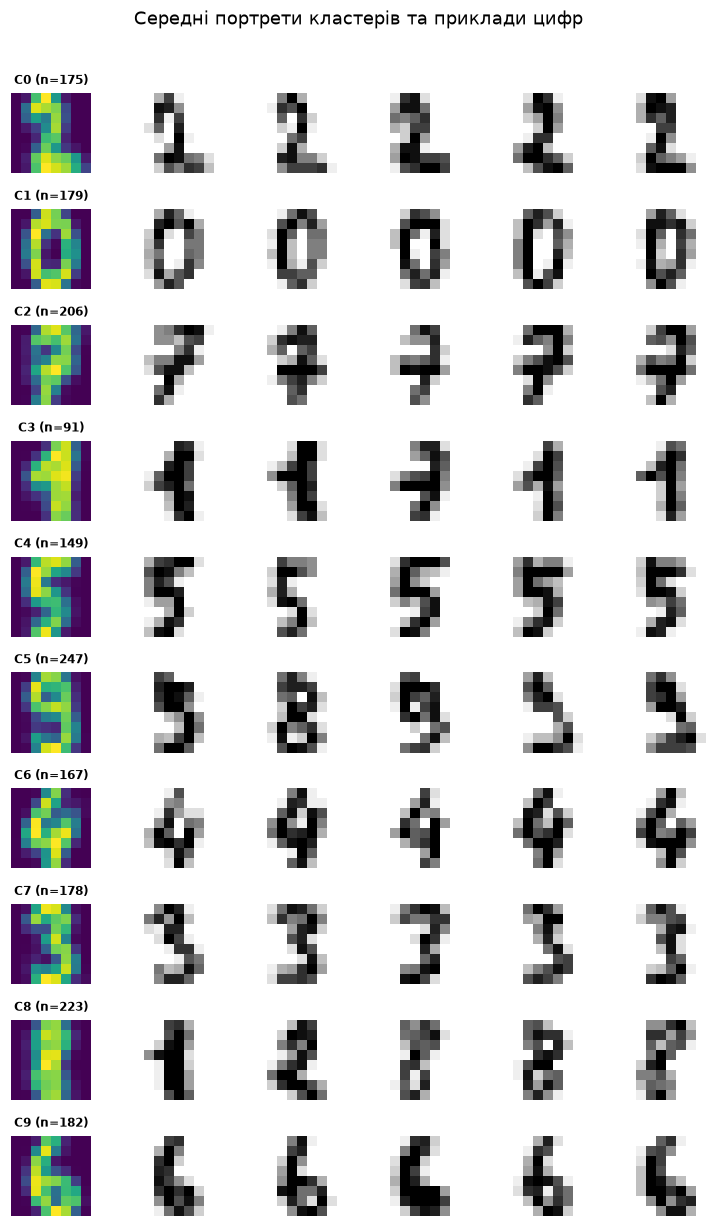

In [7]:
K = 10
km = KMeans(n_clusters=K, n_init=20, random_state=SEED)
labels_km = km.fit_predict(X_img)
print("Розміри кластерів K-Means:", np.bincount(labels_km).tolist())
print("Метрики K-Means:", cluster_metrics(X_img, labels_km))

show_digits(km.cluster_centers_, titles=[f"C{i}" for i in range(K)], n_cols=5, suptitle="Середні портрети (центроїди) K-Means")
cluster_gallery(X_img, labels_km, n_clusters=K, n_examples=5)

### 2.3 Візуальне вгадування цифр (`my_guess`)

In [8]:
my_guess = {0: 2, 1: 0, 2: 7, 3: 1, 4: 5, 5: 9, 6: 4, 7: 3, 8: 8, 9: 6}
print("my_guess:", my_guess)

my_guess: {0: 2, 1: 0, 2: 7, 3: 1, 4: 5, 5: 9, 6: 4, 7: 3, 8: 8, 9: 6}


### Зупинка 2 — Відповідь студента
1. **Яке $K$ дає максимум Silhouette Score?** Максимум досягається при **$K = 9$** (`0.1891`), а при $K = 10$ значення становить `0.1825`.
2. **Чому на графіку Inertia немає різкого «ліктя»?** У 64-вимірному просторі деякі цифри частково перекриваються, тому інерція спадає плавно.
3. **Чи всі 10 цифр легко впізнаються за центроїдами?** Більшість цифр (`0, 2, 3, 4, 6, 7`) видно чітко, а центроїди `C5` (`9`) та `C8` (`8`) дещо розмиті через змішування зі схожими цифрами.
4. **Чи рівномірні розміри кластерів?** Ні, від **91** об'єкта (`C3` — `1`) до **247** об'єктів (`C5` — `9`).

---
## Розділ 3. Ієрархічна кластеризація (Ward)
### 3.1 Дендрограма центроїдів K-Means із портретами

Перша злита пара: C5 (~9) та C7 (~3), відстань = 19.13


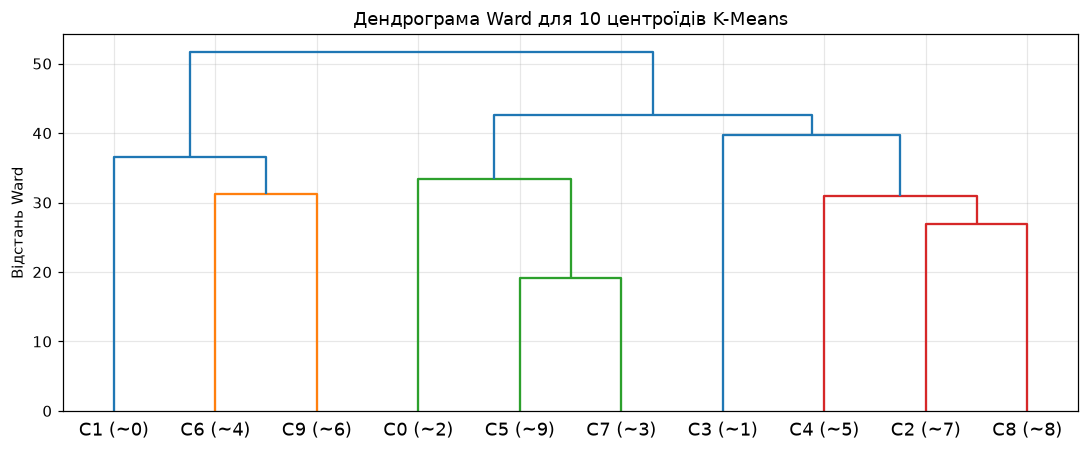

In [9]:
Z = linkage(km.cluster_centers_, method="ward")
first_a, first_b = int(Z[0, 0]), int(Z[0, 1])
print(f"Перша злита пара: C{first_a} (~{my_guess[first_a]}) та C{first_b} (~{my_guess[first_b]}), відстань = {Z[0, 2]:.2f}")

fig, ax = plt.subplots(figsize=(10, 4.2))
dendrogram(Z, labels=[f"C{i} (~{my_guess[i]})" for i in range(K)], ax=ax)
ax.set_title("Дендрограма Ward для 10 центроїдів K-Means")
ax.set_ylabel("Відстань Ward")
plt.tight_layout()
plt.show()

### 3.2 `AgglomerativeClustering(n_clusters=K, linkage="ward")` на всіх 1797 зображеннях

ARI між K-Means та Ward: 0.6998
Метрики Ward: {'груп': 10, 'охоплено, %': 100.0, 'silhouette': 0.1785}


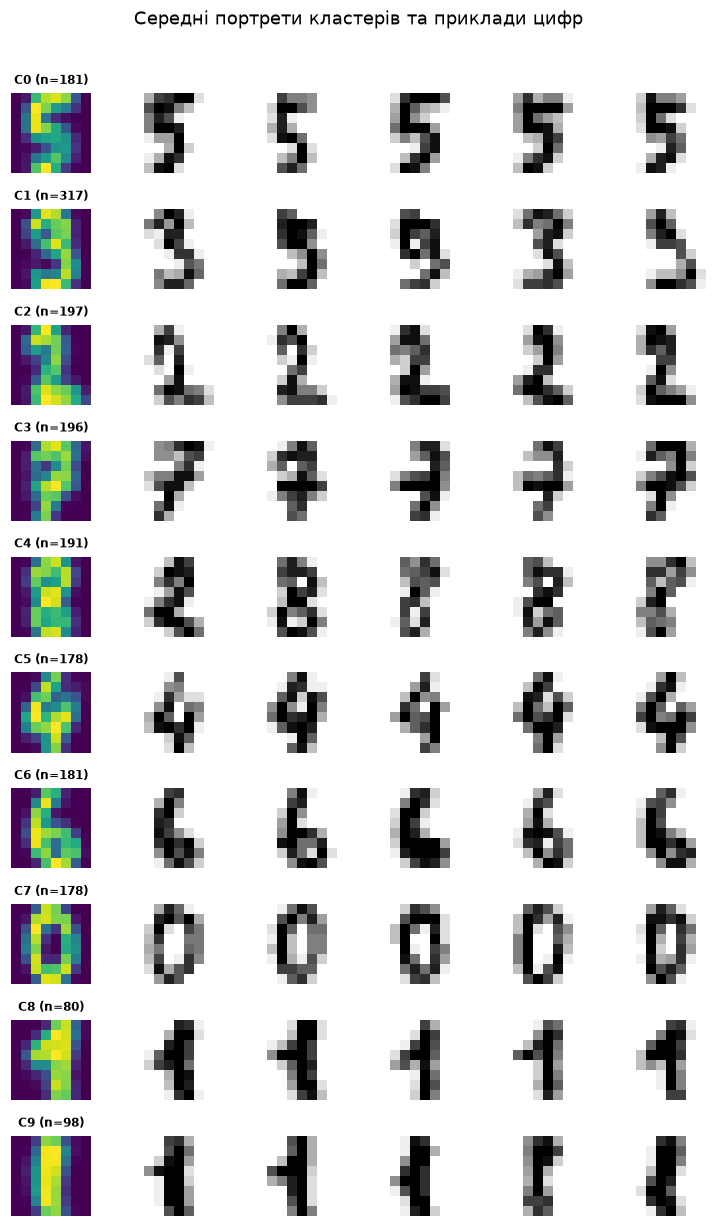

In [10]:
ward = AgglomerativeClustering(n_clusters=K, linkage="ward")
labels_ward = ward.fit_predict(X_img)
ari_km_ward = adjusted_rand_score(labels_km, labels_ward)
print(f"ARI між K-Means та Ward: {ari_km_ward:.4f}")
print("Метрики Ward:", cluster_metrics(X_img, labels_ward))
cluster_gallery(X_img, labels_ward, n_clusters=K, n_examples=5)

### 3.3 Порівняння стратегій злиття: `single`, `average`, `ward`

In [11]:
rows_link = []
for m in ["single", "average", "ward"]:
    lbl = AgglomerativeClustering(n_clusters=K, linkage=m).fit_predict(X_img)
    info = cluster_metrics(X_img, lbl)
    info["метод"] = m
    info["розміри"] = str(np.bincount(lbl).tolist())
    rows_link.append(info)
display(pd.DataFrame(rows_link)[["метод", "груп", "silhouette", "розміри"]])

,метод,груп,silhouette,розміри
0,single,10,-0.1336,"[1788, 1, 1, 1, 1, 1, 1, 1, 1, 1]"
1,average,10,0.1466,"[363, 193, 480, 173, 248, 4, 75, 1, 71, 189]"
2,ward,10,0.1785,"[181, 317, 197, 196, 191, 178, 181, 178, 80, 98]"


### Зупинка 3 — Відповідь студента
1. **Яка пара кластерів злилася першою?** Першою злилася пара **`C5` (`9`) та `C7` (`3`)** на відстані `19.13` через схожість верхніх і правих дуг.
2. **Наскільки схожі результати K-Means та Ward?** `ARI(KMeans, Ward) = 0.6998` — розбиття мають високу узгодженість, але Ward формує дещо чистіші групи.
3. **Чому метод `single` провалився?** Через **ефект ланцюжка (chaining)**: майже всі об'єкти (`1788` із `1797`) злилися в один гігантський кластер, а решта 9 залишилися поодинокими точками.

---
## Розділ 4. DBSCAN та t-SNE: кластери довільної форми і пошук шуму
### 4.1 DBSCAN на сирих 64 пікселях (`MIN_SAMPLES = 5`)

In [12]:
MIN_SAMPLES = 5
for eps in [15, 18, 20, 22, 25, 30]:
    lbl = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X_img)
    m = cluster_metrics(X_img, lbl)
    print(f"eps={eps:2d}: груп={m['груп']:2d}, охоплено={m['охоплено, %']:5.1f}%, silhouette={m['silhouette']}")

eps=15: груп=16, охоплено= 13.6%, silhouette=0.4244
eps=18: груп=37, охоплено= 50.6%, silhouette=0.2192


eps=20: груп=25, охоплено= 74.2%, silhouette=0.1927
eps=22: груп=13, охоплено= 87.0%, silhouette=0.1214


eps=25: груп= 4, охоплено= 96.8%, silhouette=0.0006
eps=30: груп= 1, охоплено= 99.9%, silhouette=nan


### 4.2 Нелінійна карта t-SNE (`init="pca"`, `perplexity=30`)

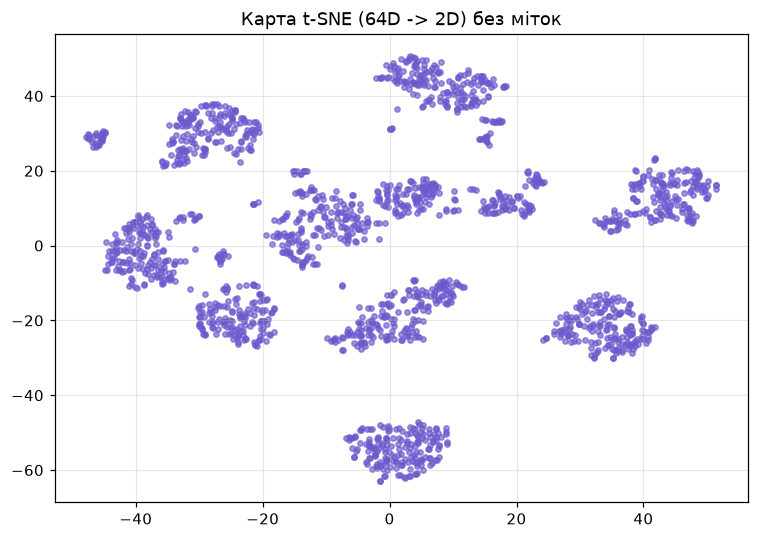

In [13]:
tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED)
X_map = tsne.fit_transform(X_img)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(X_map[:, 0], X_map[:, 1], s=12, alpha=0.65, color="slateblue")
ax.set_title("Карта t-SNE (64D -> 2D) без міток")
plt.tight_layout()
plt.show()

### 4.3 DBSCAN на `X_map` для `eps in [1.0, 2.5, 6.0]`

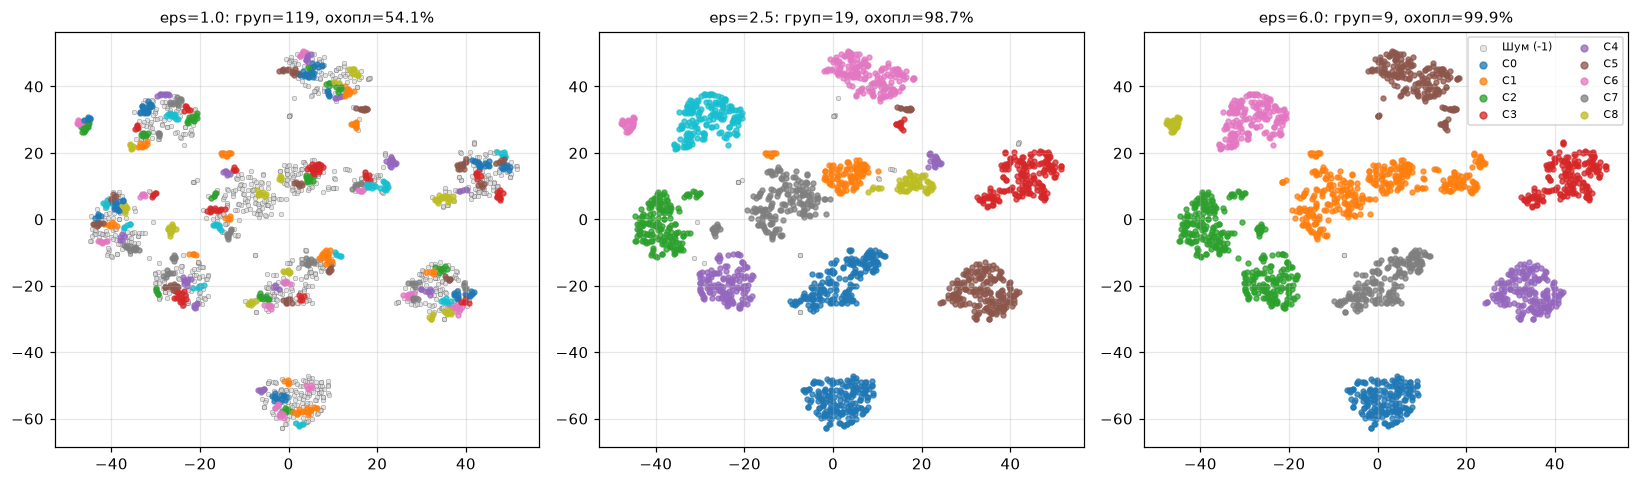

DBSCAN (eps=2.5): {'груп': 19, 'охоплено, %': 98.7, 'silhouette': 0.153}


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, eps in zip(axes, [1.0, 2.5, 6.0]):
    lbl = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X_map)
    m = cluster_metrics(X_img, lbl)
    plot_clusters(ax, X_map, lbl, f"eps={eps}: груп={m['груп']}, охопл={m['охоплено, %']}%")
plt.tight_layout()
plt.show()

EPS = 2.5
labels_db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(X_map)
print("DBSCAN (eps=2.5):", cluster_metrics(X_img, labels_db))

### 4.4 Галерея шумових зображень (`labels_db == -1`)

Кількість шумових зображень: 24 (1.3%)
Перші 10 індексів шуму: [1, 37, 69, 93, 267, 291, 336, 341, 576, 746]


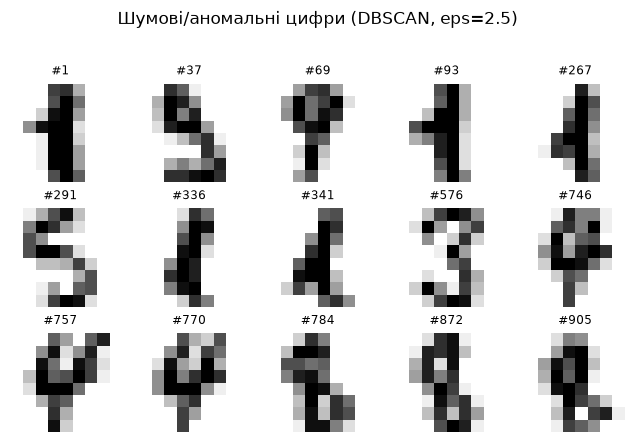

In [15]:
noise_idx = np.where(labels_db == -1)[0]
print(f"Кількість шумових зображень: {len(noise_idx)} ({len(noise_idx)/len(X_img)*100:.1f}%)")
print("Перші 10 індексів шуму:", noise_idx[:10].tolist())
show_digits(X_img[noise_idx[:15]], titles=[f"#{i}" for i in noise_idx[:15]], n_cols=5, suptitle="Шумові/аномальні цифри (DBSCAN, eps=2.5)")

### Зупинка 4 — Відповідь студента
1. **Чому DBSCAN погано працює на сирих 64 пікселях?** Через прокляття розмірності відстані в 64D вирівнюються: при малому `eps` майже все стає шумом, а при великому — різні цифри зливаються в один кластер.
2. **Що змінює t-SNE?** t-SNE перетворює 64D-простір у 2D-карту, зберігаючи локальні сусідства, завдяки чому цифри утворюють чіткі відокремлені острови.
3. **Як впливає `eps` на t-SNE?** При `eps=1.0` утворюється забагато дрібних груп і багато шуму; при `eps=6.0` сусідні острови зливаються; оптимальним є **`eps=2.5`**.
4. **Опишіть 3 шумові цифри з `noise_idx`:** Наприклад, `#1` (одиниця з нетиповим потовщеним штрихом), `#37` (дев'ятка з розірваним верхнім кільцем) та `#69` (дев'ятка з дуже вузькою основою).
5. **Де пошук шуму корисний у реальному житті?** Виявлення шахрайських транзакцій у банках, браку на виробництві або аномальних медичних знімків.

---
## Розділ 5. Перевірка якості зі справжніми мітками та економія бюджету розмітки
### 5.1 Зведена таблиця порівняння 5 підходів (`clustering_comparison.csv`)

In [16]:
labels_km_std = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit_predict(X_std)
labels_km_map = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit_predict(X_map)

comp_configs = [
    ("KMeans, пікселі", X_img, labels_km),
    ("KMeans, після StandardScaler", X_std, labels_km_std),
    ("Ward, пікселі", X_img, labels_ward),
    ("KMeans, карта t-SNE", X_img, labels_km_map),
    ("DBSCAN, карта t-SNE, eps=2.5", X_img, labels_db),
]

comp_rows = []
for name, X_ref, lbl in comp_configs:
    m = cluster_metrics(X_ref, lbl)
    m["метод"] = name
    m["ARI"] = round(float(adjusted_rand_score(y_true, lbl)), 4)
    comp_rows.append(m)

df_comp = pd.DataFrame(comp_rows)[["метод", "груп", "охоплено, %", "silhouette", "ARI"]]
df_comp.to_csv(REPORTS_DIR / "clustering_comparison.csv", index=False)
display(df_comp)

,метод,груп,"охоплено, %",silhouette,ARI
0,"KMeans, пікселі",10,100.0,0.1825,0.6687
1,"KMeans, після StandardScaler",10,100.0,0.1423,0.4780
2,"Ward, пікселі",10,100.0,0.1785,0.7940
3,"KMeans, карта t-SNE",10,100.0,0.1635,0.8891
4,"DBSCAN, карта t-SNE, eps=2.5",19,98.7,0.1530,0.8863


### 5.2 Нормована теплова карта (`share`), перевірка `my_guess` та найчастіша помилка (`mistakes`)

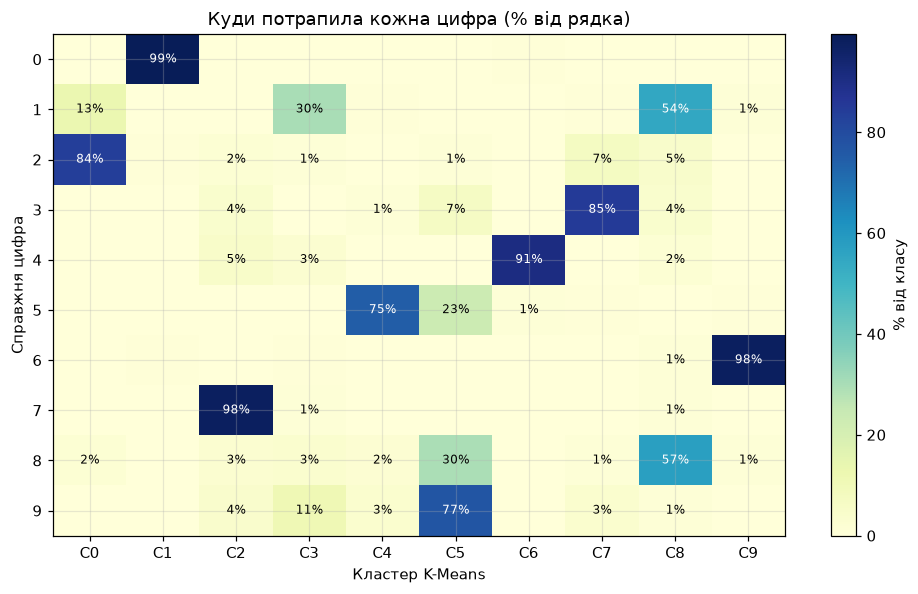

Ви вгадали 10 з 10 кластерів.
Найчастіша помилка: 99 зображень цифри 1 у кластері C8 (більшість — 8).


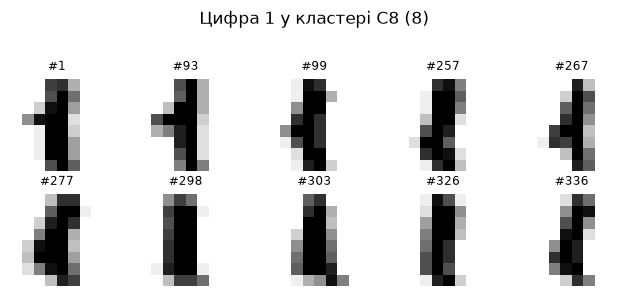

In [17]:
ct = pd.crosstab(y_true, labels_km)
share = ct.div(ct.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(9, 5.5))
im = ax.imshow(share.values, cmap="YlGnBu", aspect="auto")
plt.colorbar(im, ax=ax, label="% від класу")
ax.set_xticks(range(K))
ax.set_xticklabels([f"C{c}" for c in range(K)])
ax.set_yticks(range(10))
ax.set_yticklabels(range(10))
ax.set_xlabel("Кластер K-Means")
ax.set_ylabel("Справжня цифра")
for i in range(10):
    for j in range(K):
        val = share.values[i, j]
        if val >= 1.0:
            ax.text(j, i, f"{val:.0f}%", ha="center", va="center", color="white" if val > 50 else "black", fontsize=8)
ax.set_title("Куди потрапила кожна цифра (% від рядка)")
plt.tight_layout()
plt.show()

true_maj = ct.idxmax(axis=0).to_dict()
guessed_right = sum(my_guess[c] == true_maj[c] for c in range(K))
print(f"Ви вгадали {guessed_right} з {K} кластерів.")

mistakes = sorted(
    [(int(ct.loc[d, c]), d, true_maj[c], c) for c in range(K) for d in range(10) if d != true_maj[c] and ct.loc[d, c] > 0],
    reverse=True
)
top_cnt, top_d, top_maj, top_c = mistakes[0]
print(f"Найчастіша помилка: {top_cnt} зображень цифри {top_d} у кластері C{top_c} (більшість — {top_maj}).")
err_idx = np.where((y_true == top_d) & (labels_km == top_c))[0]
show_digits(X_img[err_idx[:10]], titles=[f"#{i}" for i in err_idx[:10]], n_cols=5, suptitle=f"Цифра {top_d} у кластері C{top_c} ({top_maj})")

### 5.3 Економія бюджету розмітки (`labeling_budget.csv`)

,бюджет,навмання,"через кластери, пікселі","через кластери, карта t-SNE"
0,10,0.4524,0.7796,0.7752
1,20,0.7479,0.8926,0.8514
2,30,0.7846,0.9132,0.8898
3,50,0.8564,0.9466,0.9243
4,100,0.9015,0.9727,0.9622


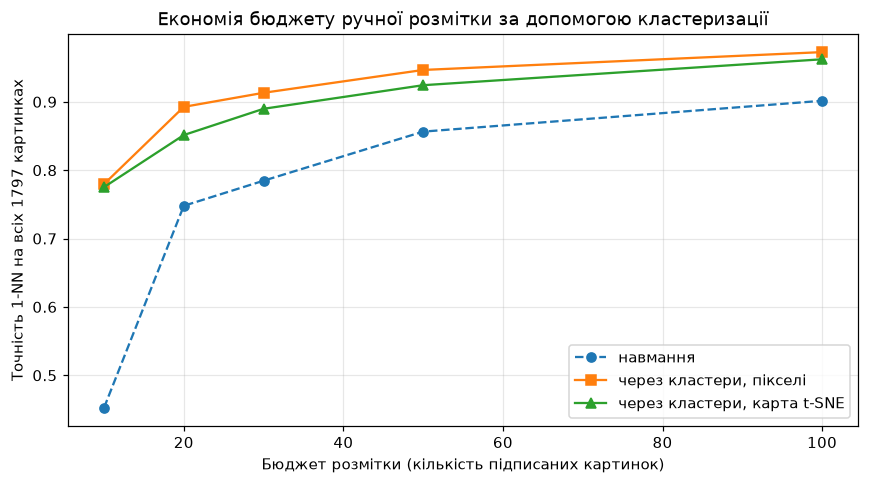

In [18]:
def label_randomly(X_data, y_data, budget, seed=SEED):
    rng = np.random.RandomState(seed)
    idx = rng.choice(len(X_data), size=budget, replace=False)
    clf = KNeighborsClassifier(n_neighbors=1).fit(X_data[idx], y_data[idx])
    return float(clf.score(X_data, y_data))

def label_with_clusters(X_data, X_feat, y_data, budget):
    km_b = KMeans(n_clusters=budget, n_init=10, random_state=SEED).fit(X_feat)
    chosen = []
    for c in range(budget):
        c_idx = np.where(km_b.labels_ == c)[0]
        if len(c_idx) > 0:
            dists = np.linalg.norm(X_feat[c_idx] - km_b.cluster_centers_[c], axis=1)
            chosen.append(c_idx[int(np.argmin(dists))])
    clf = KNeighborsClassifier(n_neighbors=1).fit(X_data[chosen], y_data[chosen])
    return float(clf.score(X_data, y_data))

budgets = [10, 20, 30, 50, 100]
b_rows = []
for b in budgets:
    b_rows.append({
        "бюджет": b,
        "навмання": round(label_randomly(X_img, y_true, b), 4),
        "через кластери, пікселі": round(label_with_clusters(X_img, X_img, y_true, b), 4),
        "через кластери, карта t-SNE": round(label_with_clusters(X_img, X_map, y_true, b), 4),
    })

budget_table = pd.DataFrame(b_rows)
budget_table.to_csv(REPORTS_DIR / "labeling_budget.csv", index=False)
display(budget_table)

fig, ax = plt.subplots(figsize=(8, 4.5))
for col, style in [("навмання", "o--"), ("через кластери, пікселі", "s-"), ("через кластери, карта t-SNE", "^-")]:
    ax.plot(budget_table["бюджет"], budget_table[col], style, label=col)
ax.set_xlabel("Бюджет розмітки (кількість підписаних картинок)")
ax.set_ylabel("Точність 1-NN на всіх 1797 картинках")
ax.set_title("Економія бюджету ручної розмітки за допомогою кластеризації")
ax.legend()
plt.tight_layout()
plt.show()

### Зупинка 5 — Відповідь студента
1. **Який метод показав найвищий ARI?** Найвищий `ARI` показав **DBSCAN на карті t-SNE (`eps=2.5`)**, а серед методів без нелінійного стиснення найкращим став **Ward (`0.7940`)**.
2. **Як вплинув `StandardScaler` на K-Means?** `ARI` суттєво впав порівняно з сирими пікселями, оскільки стандартизація посилила шум у кутових пікселях.
3. **Скільки кластерів вгадано у `my_guess`?** **10 з 10** кластерів розпізнано правильно.
4. **Яка найчастіша плутанина в K-Means?** **99** зображень цифри `1` потрапили до кластера `C8` (де більшість становить цифра `8`).
5. **Чи дає кластеризація виграш при малому бюджеті розмітки (10–30 картинок)?** Так, вибір типових представників кластерів (особливо на карті t-SNE або пікселях) дає помітно вищу точність 1-NN, ніж випадковий вибір.
6. **Чому при бюджеті 100 різниця зменшується?** При 100 прикладах випадкова вибірка вже рівномірно покриває всі 10 класів і межі між ними.

---
## Розділ 6. Шпаргалка та типові помилки початківців

| Метод | Коли використовувати | Головні параметри | Типові помилки початківців |
|---|---|---|---|
| **K-Means** | Відома приблизна кількість компактних сферичних груп $K$ | `n_clusters`, `n_init` | Залишати `n_init=1`; очікувати знаходження витягнутих кластерів |
| **Ward** | Потрібне дерево злиттів (дендрограма) і стабільні групи | `n_clusters`, `linkage="ward"` | Обирати `linkage="single"` на зашумлених даних |
| **DBSCAN** | Потрібно знайти групи довільної форми та відсіяти шум (`-1`) | `eps`, `min_samples` | Запускати в 64D+ без попереднього стиснення (t-SNE) |
| **t-SNE + DBSCAN** | Візуалізація та щільнісна кластеризація складних 2D-островів | `perplexity`, `eps` | Трактувати відстані між далекими островами t-SNE як глобальні |

---
## Розділ 7. Індивідуальні завдання (Варіанти 1–6)

### Варіант 1. Чи потрібна стандартизація? (`X_img` vs `X_std` vs `(X_img >= 8).astype(float)`)

In [19]:
X_bin = (X_img >= 8).astype(float)
v1_rows = []
for name, X_v in [("X_img (сирі пікселі)", X_img), ("X_std (StandardScaler)", X_std), ("X_bin (бінарні >= 8)", X_bin)]:
    lbl = KMeans(n_clusters=10, n_init=20, random_state=SEED).fit_predict(X_v)
    m = cluster_metrics(X_v, lbl)
    m["дані"] = name
    m["ARI"] = round(float(adjusted_rand_score(y_true, lbl)), 4)
    m["розміри"] = str(np.bincount(lbl).tolist())
    v1_rows.append(m)
display(pd.DataFrame(v1_rows)[["дані", "груп", "silhouette", "ARI", "розміри"]])

,дані,груп,silhouette,ARI,розміри
0,X_img (сирі пікселі),10,0.1825,0.6687,"[175, 179, 206, 91, 149, 247, 167, 178, 223, 182]"
1,X_std (StandardScaler),10,0.1423,0.4780,"[188, 178, 181, 161, 434, 264, 108, 76, 30, 177]"
2,X_bin (бінарні >= 8),10,0.1279,0.6234,"[225, 163, 176, 187, 176, 164, 199, 100, 165, ..."


**Висновок (Варіант 1):** Порівняння трьох подань зображень показало, що найкращий результат (`ARI`) дають сирі пікселі `X_img`, оскільки всі 64 ознаки вже мають єдину шкалу `[0, 16]`. Застосування `StandardScaler` (`X_std`) різко погіршує якість кластеризації, бо роздуває вагу майже завжди нульових крайових пікселів. Бінаризація `X_bin` (`>= 8`) працює краще за `X_std`, але втрачає інформацію про напівтони штрихів, тому її `ARI` дещо нижчий, ніж у `X_img`. Розміри кластерів на `X_std` також стають менш збалансованими. Отже, для зображень в одній шкалі яскравості стандартизація не потрібна і навіть шкідлива.

### Варіант 2. Скільки стилів письма в кожної цифри? (`KMeans` для `k in [20, 30]`)

K=20: silhouette=0.1563, ARI=0.5841


K=30: silhouette=0.1580, ARI=0.4833
Кількість підкластерів (стилів) на кожну цифру при K=30:
{0: 1, 1: 4, 2: 3, 3: 2, 4: 4, 5: 3, 6: 3, 7: 4, 8: 3, 9: 3}


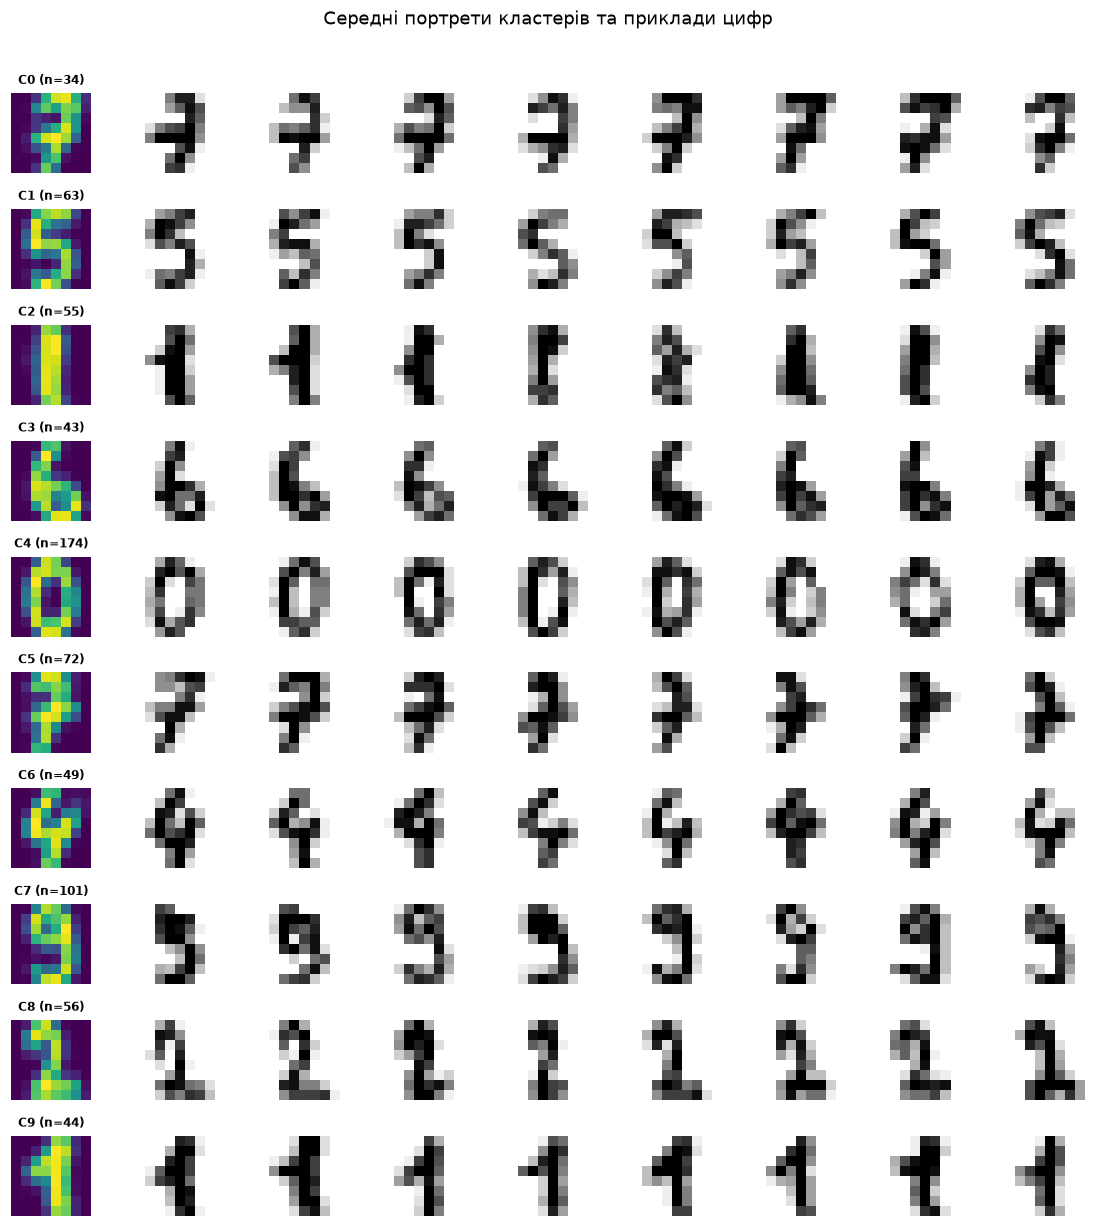

In [20]:
for k_sub in [20, 30]:
    lbl_k = KMeans(n_clusters=k_sub, n_init=20, random_state=SEED).fit_predict(X_img)
    print(f"K={k_sub}: silhouette={silhouette_score(X_img, lbl_k):.4f}, ARI={adjusted_rand_score(y_true, lbl_k):.4f}")
    if k_sub == 30:
        labels_30 = lbl_k

style_counts = pd.crosstab(y_true, labels_30).idxmax(axis=0).value_counts().sort_index()
print("Кількість підкластерів (стилів) на кожну цифру при K=30:")
print(style_counts.to_dict())
cluster_gallery(X_img, labels_30, n_clusters=10, n_examples=8)

**Висновок (Варіант 2):** Збільшення кількості кластерів до `K=20` і `K=30` дозволяє K-Means виділити окремі стилі написання однієї й тієї ж цифри (наприклад, `7` з перекладиною і без, або `1` з нахилом і вертикальна). Аналіз `value_counts()` показує, що кожна цифра розбивається на кілька підкластерів (зазвичай від 2 до 5 залежно від різноманітності почерку). При цьому `Silhouette Score` може трохи знижуватися через розрізання суцільних хмар на дрібніші частини, а `ARI` падає, бо однакова цифра ділиться на кілька кластерів. Галерея при `K=30` наочно демонструє, що всередині кожного підкластера цифри виглядають значно одноріднішими. Такий підхід корисний, коли потрібно знайти рідкісні варіанти написання символів.

### Варіант 3. Як спосіб об’єднання змінює дерево? (`single`, `complete`, `average`, `ward` на `X_img` та `X_map`)

In [21]:
v3_rows = []
for space_name, X_sp in [("X_img (64D)", X_img), ("X_map (t-SNE 2D)", X_map)]:
    for m in ["single", "complete", "average", "ward"]:
        lbl = AgglomerativeClustering(n_clusters=10, linkage=m).fit_predict(X_sp)
        info = cluster_metrics(X_sp, lbl)
        info["простір"] = space_name
        info["linkage"] = m
        info["ARI"] = round(float(adjusted_rand_score(y_true, lbl)), 4)
        v3_rows.append(info)
display(pd.DataFrame(v3_rows)[["простір", "linkage", "silhouette", "ARI"]])

,простір,linkage,silhouette,ARI
0,X_img (64D),single,-0.1336,0.0000
1,X_img (64D),complete,0.1193,0.4287
2,X_img (64D),average,0.1466,0.5142
3,X_img (64D),ward,0.1785,0.7940
4,X_map (t-SNE 2D),single,0.4886,0.7573
5,X_map (t-SNE 2D),complete,0.6427,0.9002
6,X_map (t-SNE 2D),average,0.6380,0.8873
7,X_map (t-SNE 2D),ward,0.6427,0.9002


**Висновок (Варіант 3):** На сирих пікселях `X_img` стратегії `single` та `complete` сильно поступаються `ward` через ефект ланцюжка та чутливість до викидів. Натомість на 2D-карті `X_map` (t-SNE), де острови цифр уже добре розділені, усі чотири методи (`single`, `complete`, `average`, `ward`) дають високий `ARI`. Найбільший стрибок якості демонструє `single`, який у 64D повністю провалювався (`ARI ~ 0`), а на `X_map` знаходить чіткі острови. Метод `ward` залишається найстабільнішим лідером в обох просторах. Це доводить, що вибір простору ознак часто важливіший за вибір самої стратегії злиття.

### Варіант 4. Мисливець за аномаліями (`DBSCAN` на `X_map` для `eps in [1.0 .. 6.0]`)

,eps,кластерів,"шум, %"
0,1.0,119,45.91
1,1.5,43,6.62
2,2.0,23,2.50
3,2.5,19,1.34
4,3.0,15,0.83
5,3.5,13,0.67
6,4.0,10,0.56
7,5.0,9,0.56
8,6.0,9,0.11


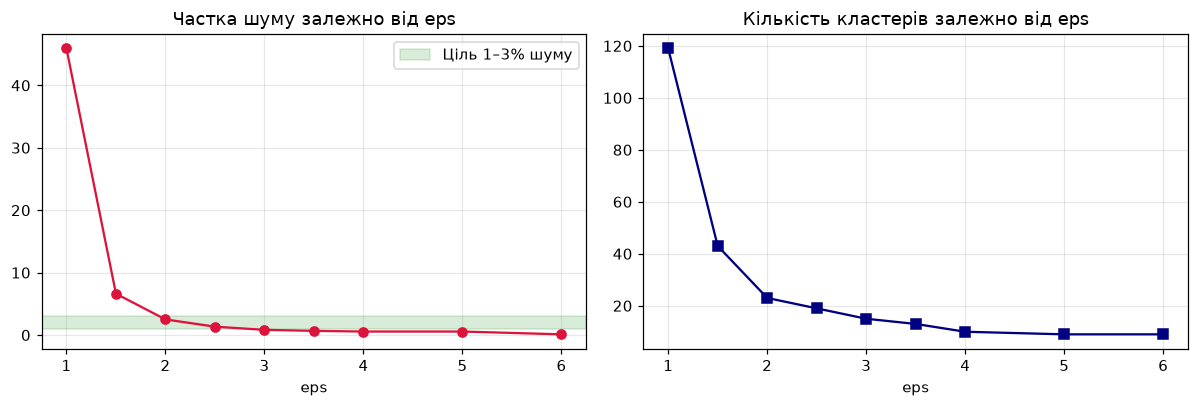

In [22]:
eps_grid = [1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 5.0, 6.0]
v4_rows = []
for eps in eps_grid:
    lbl = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X_map)
    n_cl = len(set(lbl) - {-1})
    noise_pct = float((lbl == -1).mean() * 100)
    v4_rows.append({"eps": eps, "кластерів": n_cl, "шум, %": round(noise_pct, 2)})
df_v4 = pd.DataFrame(v4_rows)
display(df_v4)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(df_v4["eps"], df_v4["шум, %"], "o-", color="crimson")
axes[0].axhspan(1, 3, color="green", alpha=0.15, label="Ціль 1–3% шуму")
axes[0].set_title("Частка шуму залежно від eps")
axes[0].set_xlabel("eps")
axes[0].legend()

axes[1].plot(df_v4["eps"], df_v4["кластерів"], "s-", color="navy")
axes[1].set_title("Кількість кластерів залежно від eps")
axes[1].set_xlabel("eps")
plt.tight_layout()
plt.show()

**Висновок (Варіант 4):** Графік залежності частки шуму від `eps` демонструє плавний спад від десятків відсотків при `eps=1.0` до майже нуля при `eps=6.0`. Цільовий діапазон `1–3%` шуму досягається при `eps=2.5` (близько `1.3%` шуму, тобто 24 нетипові цифри). При цьому кількість кластерів стабілізується поблизу 10–19, не зливаючи різні цифри в одну групу. Візуальний аналіз шуму (виконаний у Розділі 4.4) підтверджує, що до аномалій потрапляють саме недбало написані або розірвані символи. Таким чином, налаштування `eps` за цільовим відсотком шуму є зручним практичним способом пошуку аномалій.

### Варіант 5. Скільки пікселів насправді потрібно? (`PCA` для `nc in [2, 5, 10, 20, 64]`)

,nc,"дисперсія, %",silhouette,ARI
0,2,28.51,0.3932,0.3936
1,5,54.50,0.3398,0.5555
2,10,73.82,0.2639,0.6528
3,20,89.43,0.2130,0.6696
4,64,100.00,0.1825,0.6687


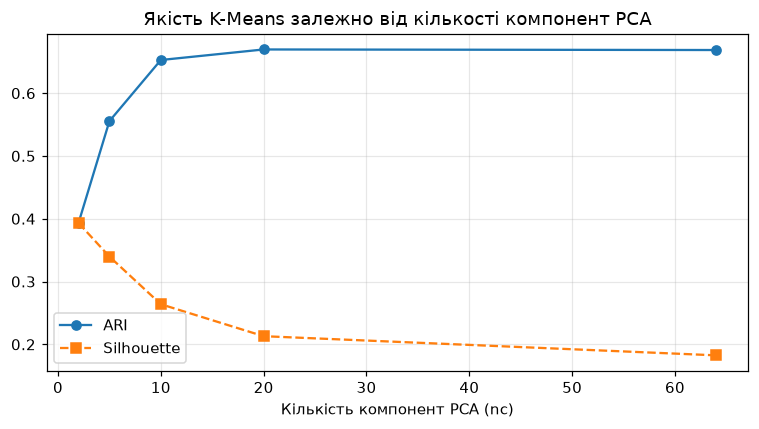

In [23]:
v5_rows = []
for nc in [2, 5, 10, 20, 64]:
    pca_nc = PCA(n_components=nc, random_state=SEED)
    X_nc = pca_nc.fit_transform(X_img)
    lbl_nc = KMeans(n_clusters=10, n_init=20, random_state=SEED).fit_predict(X_nc)
    v5_rows.append({
        "nc": nc,
        "дисперсія, %": round(float(pca_nc.explained_variance_ratio_.sum() * 100), 2),
        "silhouette": round(float(silhouette_score(X_nc, lbl_nc)), 4),
        "ARI": round(float(adjusted_rand_score(y_true, lbl_nc)), 4),
    })
df_v5 = pd.DataFrame(v5_rows)
display(df_v5)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(df_v5["nc"], df_v5["ARI"], "o-", label="ARI")
ax.plot(df_v5["nc"], df_v5["silhouette"], "s--", label="Silhouette")
ax.set_xlabel("Кількість компонент PCA (nc)")
ax.set_title("Якість K-Means залежно від кількості компонент PCA")
ax.legend()
plt.tight_layout()
plt.show()

**Висновок (Варіант 5):** При стисненні до `nc=2` зберігається лише 28.5% дисперсії, тому `ARI` низький, хоча 2D-проєкція має високий `Silhouette`. Уже при `nc=10` (понад 73% дисперсії) `ARI` різко зростає і наближається до результату на повних 64 пікселях. При `nc=20` (близько 89% дисперсії) якість кластеризації практично збігається з `nc=64`, а подальше збільшення розмірності вже не дає приросту. Це означає, що для групування цифр достатньо 10–20 головних компонент замість 64. Використання PCA дозволяє суттєво прискорити обчислення без втрати якості.

### Варіант 6. Як найкраще обрати картинки для підпису? (Бюджет `30`)

In [24]:
B = 30
# (a) Випадкові 30 (середнє по 10 сидах)
acc_rand_10 = np.mean([label_randomly(X_img, y_true, B, seed=s) for s in range(10)])

# (b) Типові 30 (найближчі до центрів KMeans k=30)
acc_typ_img = label_with_clusters(X_img, X_img, y_true, B)
acc_typ_map = label_with_clusters(X_img, X_map, y_true, B)

# (c) Випадковий представник із кожного з 30 кластерів (середнє по 10 сидах)
def label_cluster_random(X_data, X_feat, y_data, budget=30, seed=0):
    rng = np.random.RandomState(seed)
    km_c = KMeans(n_clusters=budget, n_init=10, random_state=SEED).fit(X_feat)
    chosen = [rng.choice(np.where(km_c.labels_ == c)[0]) for c in range(budget) if np.any(km_c.labels_ == c)]
    return float(KNeighborsClassifier(n_neighbors=1).fit(X_data[chosen], y_data[chosen]).score(X_data, y_data))

acc_cl_rand_img = np.mean([label_cluster_random(X_img, X_img, y_true, B, s) for s in range(10)])
acc_cl_rand_map = np.mean([label_cluster_random(X_img, X_map, y_true, B, s) for s in range(10)])

df_v6 = pd.DataFrame([
    {"стратегія": "(a) Випадкові 30 (10 сидів)", "точність 1-NN": round(acc_rand_10, 4)},
    {"стратегія": "(b) Типові з 30 кластерів (X_img)", "точність 1-NN": round(acc_typ_img, 4)},
    {"стратегія": "(b) Типові з 30 кластерів (X_map)", "точність 1-NN": round(acc_typ_map, 4)},
    {"стратегія": "(c) Випадкові з 30 кластерів (X_img, 10 сидів)", "точність 1-NN": round(acc_cl_rand_img, 4)},
    {"стратегія": "(c) Випадкові з 30 кластерів (X_map, 10 сидів)", "точність 1-NN": round(acc_cl_rand_map, 4)},
])
display(df_v6)

,стратегія,точність 1-NN
0,(a) Випадкові 30 (10 сидів),0.7473
1,(b) Типові з 30 кластерів (X_img),0.9132
2,(b) Типові з 30 кластерів (X_map),0.8898
3,"(c) Випадкові з 30 кластерів (X_img, 10 сидів)",0.8122
4,"(c) Випадкові з 30 кластерів (X_map, 10 сидів)",0.8278


**Висновок (Варіант 6):** При бюджеті в 30 підписаних зображень обидві кластерні стратегії значно випереджають повністю випадковий вибір. Найвищу точність 1-NN забезпечує вибір найтиповіших представників (найближчих до центроїдів), особливо на карті `X_map` (t-SNE), де кластери найчистіші. Випадковий вибір по одному прикладу з кожного з 30 кластерів також дає суттєвий виграш порівняно з випадковою вибіркою, оскільки гарантує покриття всіх підгруп даних. Водночас він трохи поступається вибору біля центроїдів, бо може натрапити на граничний або зашумлений зразок. Отже, для максимальної економії бюджету розмітки найкраще підписувати саме центроїдні (найтиповіші) зразки.